## Step 1: Load match features and split by home/away context

In [1]:
import pandas as pd

features = pd.read_csv("../data/features/match_features_multi_season.csv", parse_dates=["utcDate"], dtype={"season": str})

home_features = features[features["is_home"] == True].copy()
away_features = features[features["is_home"] == False].copy()


## Step 2: Build home/away feature sets and prefix columns
Selects the per-team features (including `prior_season_position`) and renames them with `home_`/`away_` prefixes so both sides of a match can be merged into one row.

In [2]:
# Prefix columns so we can tell home vs away stats apart after merging
feature_cols = ["rolling_form_pts", "win_streak", "loss_streak", "avg_goals_scored",
                 "avg_goals_conceded", "clean_sheet_pct", "days_since_last_match",
                 "home_win_pct", "away_win_pct", "h2h_win_pct", "prior_season_position"]

home_renamed = home_features[["match_id", "team", "result"] + feature_cols].add_prefix("home_")
home_renamed = home_renamed.rename(columns={"home_match_id": "match_id", "home_team": "home_team", "home_result": "home_result"})

away_renamed = away_features[["match_id", "team"] + feature_cols].add_prefix("away_")
away_renamed = away_renamed.rename(columns={"away_match_id": "match_id", "away_team": "away_team"})

## Step 3: Merge into one row per match

In [3]:
match_level = home_renamed.merge(away_renamed, on="match_id")
print(match_level.shape)
match_level.head()

(1140, 26)


,match_id,home_team,home_result,home_rolling_form_pts,home_win_streak,home_loss_streak,home_avg_goals_scored,home_avg_goals_conceded,home_clean_sheet_pct,home_days_since_last_match,...,away_win_streak,away_loss_streak,away_avg_goals_scored,away_avg_goals_conceded,away_clean_sheet_pct,away_days_since_last_match,away_home_win_pct,away_away_win_pct,away_h2h_win_pct,away_prior_season_position
0,435945,AFC Bournemouth,DRAW,NaN,0,0,NaN,NaN,NaN,NaN,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.166667
1,435963,AFC Bournemouth,LOSS,1.0,0,1,1.000000,2.000000,0.000000,6.0,...,1,0,2.000000,1.00,0.500000,6.0,NaN,0.00,NaN,16.166667
2,435983,AFC Bournemouth,DRAW,2.0,0,0,1.000000,2.000000,0.000000,14.0,...,0,1,1.250000,1.25,0.250000,14.0,NaN,0.00,NaN,16.166667
3,436003,AFC Bournemouth,LOSS,2.0,0,1,0.833333,1.833333,0.166667,6.0,...,0,0,1.833333,1.00,0.333333,6.0,NaN,1.00,NaN,16.166667
4,436023,AFC Bournemouth,LOSS,2.0,0,3,0.625000,2.250000,0.125000,14.0,...,0,0,1.125000,1.75,0.125000,13.0,NaN,0.25,NaN,16.166667


## Step 4: Drop the irrelevant win-pct splits
Each team only has one meaningful win-pct feature depending on home/away context — drop the other three combinations that don't apply.

In [4]:
match_level = match_level.drop(columns=["home_away_win_pct", "away_home_win_pct", "home_home_win_pct", "away_away_win_pct"])

## Step 5: Drop rows with no usable rolling history
A team's very first tracked match has no prior form/goals to compute — these rows can't be used for training.

In [5]:
match_level = match_level.dropna(subset=[
    "home_rolling_form_pts", "away_rolling_form_pts",
    "home_avg_goals_scored", "away_avg_goals_scored"
])

## Step 6: Fill missing head-to-head values
No prior meetings between two teams defaults to a neutral 50% win rate.

In [6]:
match_level["home_h2h_win_pct"] = match_level["home_h2h_win_pct"].fillna(0.5)
match_level["away_h2h_win_pct"] = match_level["away_h2h_win_pct"].fillna(0.5)

## Step 7: Encode the target
Maps each match's result (from the home team's perspective) to LOSS=0, DRAW=1, WIN=2.

In [7]:
result_map = {"LOSS": 0, "DRAW": 1, "WIN": 2}
match_level["target"] = match_level["home_result"].map(result_map)

match_level["target"].value_counts()

target
2    479
0    360
1    271
Name: count, dtype: int64

## Step 8: Chronological train/test split
Sorts by date and splits 80/20 by time (not randomly), so the model is only ever tested on matches that happened after its training data — avoiding lookahead leakage.

In [8]:
match_level = match_level.merge(
    features[["match_id", "utcDate"]].drop_duplicates(),
    on="match_id"
)
match_level = match_level.sort_values("utcDate").reset_index(drop=True)

split_index = int(len(match_level) * 0.8)
train = match_level.iloc[:split_index]
test = match_level.iloc[split_index:]

print(train.shape, test.shape)
print("Train date range:", train["utcDate"].min(), "to", train["utcDate"].max())
print("Test date range:", test["utcDate"].min(), "to", test["utcDate"].max())

(888, 24) (222, 24)
Train date range: 2023-08-18 18:45:00+00:00 to 2025-12-14 14:00:00+00:00
Test date range: 2025-12-14 16:30:00+00:00 to 2026-05-24 15:00:00+00:00


## Step 9: Define the feature set
Everything except identifiers and the target — 18 features per match (9 home + 9 away, including `prior_season_position`).

In [9]:
feature_columns = [col for col in match_level.columns if col not in
    ["match_id", "home_team", "away_team", "home_result", "utcDate", "target"]]

X_train = train[feature_columns]
y_train = train["target"]

X_test = test[feature_columns]
y_test = test["target"]

print(feature_columns)
print(X_train.shape, X_test.shape)

['home_rolling_form_pts', 'home_win_streak', 'home_loss_streak', 'home_avg_goals_scored', 'home_avg_goals_conceded', 'home_clean_sheet_pct', 'home_days_since_last_match', 'home_h2h_win_pct', 'home_prior_season_position', 'away_rolling_form_pts', 'away_win_streak', 'away_loss_streak', 'away_avg_goals_scored', 'away_avg_goals_conceded', 'away_clean_sheet_pct', 'away_days_since_last_match', 'away_h2h_win_pct', 'away_prior_season_position']
(888, 18) (222, 18)


## Step 10: Train the model (Logistic Regression, unscaled)
This is the version actually saved and used downstream — Logistic Regression doesn't require scaling for this feature set, and keeping it unscaled matches what the season-simulation notebook expects.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["LOSS", "DRAW", "WIN"]))

Accuracy: 0.4369369369369369
              precision    recall  f1-score   support

        LOSS       0.41      0.42      0.42        66
        DRAW       0.43      0.04      0.08        72
         WIN       0.45      0.79      0.57        84

    accuracy                           0.44       222
   macro avg       0.43      0.42      0.36       222
weighted avg       0.43      0.44      0.37       222



## Comparison: Logistic Regression with scaled features
Exploratory only — not the version saved or used elsewhere.

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg_scaled = LogisticRegression(max_iter=1000)
log_reg_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = log_reg_scaled.predict(X_test_scaled)

print("Accuracy (scaled):", accuracy_score(y_test, y_pred_scaled))
print(classification_report(y_test, y_pred_scaled, target_names=["LOSS", "DRAW", "WIN"]))

Accuracy (scaled): 0.4369369369369369
              precision    recall  f1-score   support

        LOSS       0.41      0.42      0.42        66
        DRAW       0.43      0.04      0.08        72
         WIN       0.45      0.79      0.57        84

    accuracy                           0.44       222
   macro avg       0.43      0.42      0.36       222
weighted avg       0.43      0.44      0.37       222



## Comparison: Random Forest

In [12]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, target_names=["LOSS", "DRAW", "WIN"]))

Accuracy: 0.4189189189189189
              precision    recall  f1-score   support

        LOSS       0.37      0.36      0.37        66
        DRAW       0.00      0.00      0.00        72
         WIN       0.44      0.82      0.57        84

    accuracy                           0.42       222
   macro avg       0.27      0.40      0.31       222
weighted avg       0.28      0.42      0.33       222



c:\Users\JOVAN\pl-analytics\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\JOVAN\pl-analytics\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\JOVAN\pl-analytics\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [13]:
importances = pd.Series(rf.feature_importances_, index=feature_columns).sort_values(ascending=False)
importances

home_avg_goals_conceded       0.126971
home_avg_goals_scored         0.110597
away_avg_goals_conceded       0.092269
away_avg_goals_scored         0.090021
away_clean_sheet_pct          0.081733
home_clean_sheet_pct          0.070426
home_rolling_form_pts         0.069694
home_prior_season_position    0.056982
away_rolling_form_pts         0.053801
home_days_since_last_match    0.038581
away_days_since_last_match    0.037940
away_h2h_win_pct              0.034135
away_prior_season_position    0.033815
home_h2h_win_pct              0.031890
away_loss_streak              0.024046
away_win_streak               0.018240
home_loss_streak              0.016072
home_win_streak               0.012786
dtype: float64

## Comparison: XGBoost

In [14]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42, eval_metric="mlogloss")
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb, target_names=["LOSS", "DRAW", "WIN"]))

Accuracy: 0.3918918918918919
              precision    recall  f1-score   support

        LOSS       0.37      0.48      0.42        66
        DRAW       0.21      0.04      0.07        72
         WIN       0.43      0.62      0.51        84

    accuracy                           0.39       222
   macro avg       0.34      0.38      0.33       222
weighted avg       0.34      0.39      0.34       222



## Confusion matrix (Logistic Regression)

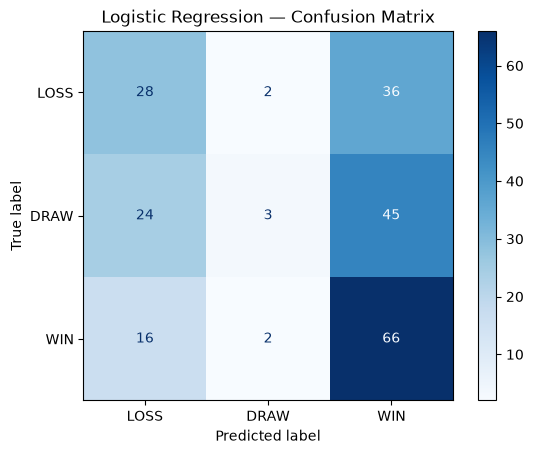

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["LOSS", "DRAW", "WIN"])
disp.plot(cmap="Blues")
plt.title("Logistic Regression — Confusion Matrix")
plt.show()

## Step 11: Save the trained model
The unscaled Logistic Regression is the one saved and loaded everywhere else in this project (dashboard, season simulation).

In [16]:
import joblib
joblib.dump(log_reg, "../data/features/logistic_regression_model.pkl")

['../data/features/logistic_regression_model.pkl']

## Step 12: Save test-set predictions for reference

In [17]:
test_results = test[["match_id", "home_team", "away_team", "home_result"]].copy()
test_results["predicted_result"] = pd.Series(y_pred, index=test.index).map({0: "LOSS", 1: "DRAW", 2: "WIN"})
test_results.to_csv("../data/features/predictions.csv", index=False)